# Unemployment Analysis with Python
**Oasis Infobyte Internship · Python Track · Task 2**

**Objective:** Explore unemployment data for India to uncover regional and temporal trends, with a focus on the impact of the COVID-19 pandemic.

**Dataset:** "Unemployment in India" from Kaggle (state-wise estimated unemployment rate, employed count and labour participation rate).

**Before running:** download the CSV from Kaggle and place it in the same folder as this notebook (see the file name in Section 2).

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

## 2. Load the Data

In [2]:
CSV_PATH = "Unemployment in India.csv"   # change this if your downloaded file has a different name

raw = pd.read_csv(CSV_PATH)
df = raw.copy()

# Kaggle column names often contain stray spaces, so strip them first
df.columns = df.columns.str.strip()

def standardise(col):
    """Give the columns short, consistent names."""
    c = col.lower()
    if "unemployment" in c:   return "unemployment_rate"
    if "participation" in c:  return "labour_participation_rate"
    if "employed" in c:       return "employed"
    if c == "date":           return "date"
    if c == "frequency":      return "frequency"
    if c == "region":         return "region"
    if c == "area":           return "area"
    return col

df.columns = [standardise(c) for c in df.columns]
df.head()

,region,date,frequency,unemployment_rate,employed,labour_participation_rate,area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 3. Data Inspection and Cleaning

### 3.1 Shape, data types and null values

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nNull values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape (rows, columns): (768, 7)

Data types:
region                           str
date                             str
frequency                        str
unemployment_rate            float64
employed                     float64
labour_participation_rate    float64
area                             str
dtype: object

Null values per column:
region                       28
date                         28
frequency                    28
unemployment_rate            28
employed                     28
labour_participation_rate    28
area                         28
dtype: int64

Duplicate rows: 27


### 3.2 Cleaning and type conversion

In [4]:
# Remove completely empty / incomplete rows
required = ["region", "date", "unemployment_rate", "employed", "labour_participation_rate"]
before = len(df)
df = df.dropna(subset=required).drop_duplicates().reset_index(drop=True)
print(f"Rows removed: {before - len(df)}")

# Strip whitespace from text columns
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# Convert the date column (day-first format, e.g. 31-05-2019)
df["date"] = pd.to_datetime(df["date"], dayfirst=True)

# Helpful time features
df["year_month"] = df["date"].dt.to_period("M")
df["month"] = df["date"].dt.month_name()

print("\nDate range:", df["date"].min().date(), "to", df["date"].max().date())
print("Number of regions:", df["region"].nunique())
df.dtypes

Rows removed: 28

Date range: 2019-05-31 to 2020-06-30
Number of regions: 28


region                                  str
date                         datetime64[us]
frequency                               str
unemployment_rate                   float64
employed                            float64
labour_participation_rate           float64
area                                    str
year_month                        period[M]
month                                   str
dtype: object

### 3.3 Descriptive statistics

In [5]:
df[["unemployment_rate", "employed", "labour_participation_rate"]].describe().round(2)

,unemployment_rate,employed,labour_participation_rate
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.50
max,76.74,45777509.00,72.57


**Observations:** The dataset records monthly unemployment figures by state. After removing empty rows and converting the date column to a proper datetime type, the data is ready for analysis. The unemployment rate shows a wide spread between its minimum and maximum, which hints at strong regional and time-based differences.

## 4. Exploratory Data Analysis

### 4.1 Region-wise average rates

In [6]:
region_avg = (
    df.groupby("region")[["unemployment_rate", "employed", "labour_participation_rate"]]
      .mean()
      .sort_values("unemployment_rate", ascending=False)
      .round(2)
)
region_avg

,unemployment_rate,employed,labour_participation_rate
region,,,
Tripura,28.35,717002.64,61.82
Haryana,26.28,3557072.46,42.74
Jharkhand,20.58,4469240.43,41.67
Bihar,18.92,12366189.14,38.15
Himachal Pradesh,18.54,1059823.71,44.22
Delhi,16.50,2627512.86,38.93
Jammu & Kashmir,16.19,1799931.67,41.03
Chandigarh,15.99,316831.25,39.34
Rajasthan,14.06,10041064.75,39.97


**Observations:** Average unemployment differs widely between states. Tripura has the highest average at 28.35%, while Meghalaya has the lowest at 4.80%, a gap of more than 23 percentage points. 

### 4.2 Month-wise trend (all regions averaged)

year_month
2019-05     8.87
2019-06     9.30
2019-07     9.03
2019-08     9.64
2019-09     9.05
2019-10     9.90
2019-11     9.87
2019-12     9.50
2020-01     9.95
2020-02     9.96
2020-03    10.70
2020-04    23.64
2020-05    24.88
2020-06    11.90
Freq: M, Name: unemployment_rate, dtype: float64


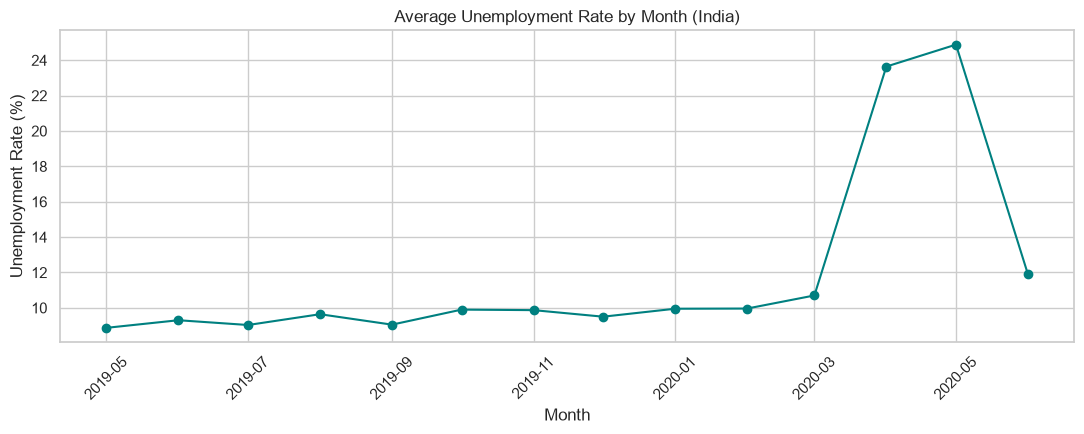

In [7]:
monthly = df.groupby("year_month")["unemployment_rate"].mean().round(2)
print(monthly)

plt.figure(figsize=(11, 4.5))
monthly.index = monthly.index.to_timestamp()
plt.plot(monthly.index, monthly.values, marker="o", color="teal")
plt.title("Average Unemployment Rate by Month (India)")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observations:** The national average stays fairly steady at around [x]% through late 2019 and early 2020, then rises sharply when lockdowns began. It peaks in May 2020 at 24.88%. 

## 5. Time-Series Line Chart for Major States

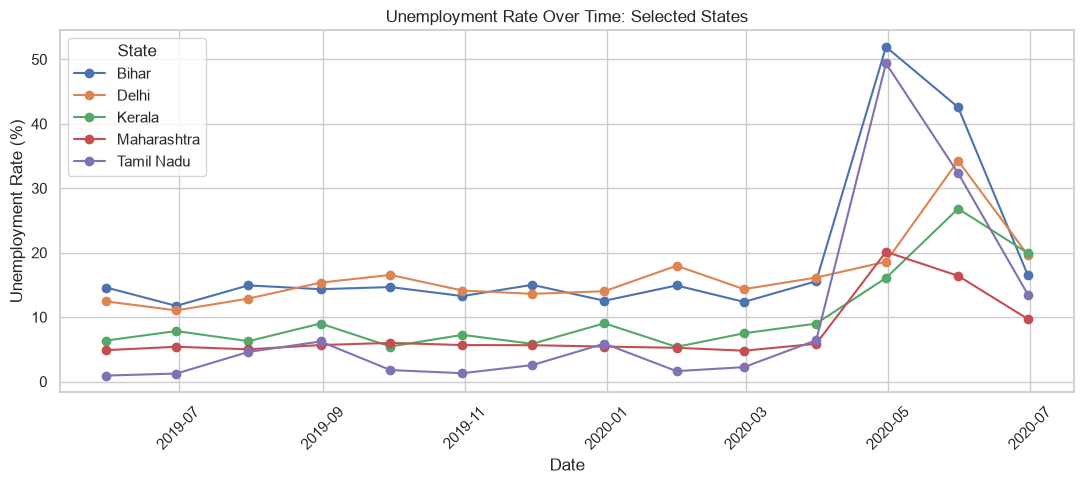

In [8]:
preferred = ["Maharashtra", "Delhi", "Kerala", "Bihar", "Tamil Nadu"]
available = set(df["region"].unique())
chosen = [s for s in preferred if s in available]

# Fall back to the highest-unemployment states if the preferred ones are missing
if len(chosen) < 3:
    chosen = region_avg.head(5).index.tolist()

pivot = (
    df[df["region"].isin(chosen)]
      .groupby(["date", "region"])["unemployment_rate"].mean()
      .unstack()
)

plt.figure(figsize=(11, 5))
for state in pivot.columns:
    plt.plot(pivot.index, pivot[state], marker="o", label=state)
plt.title("Unemployment Rate Over Time: Selected States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend(title="State")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observations:** All the selected states show a spike around April to May 2020, but the size of the jump differs. This shows that the pandemic's impact was uneven across regions.

## 6. Top 10 States by Average Unemployment Rate

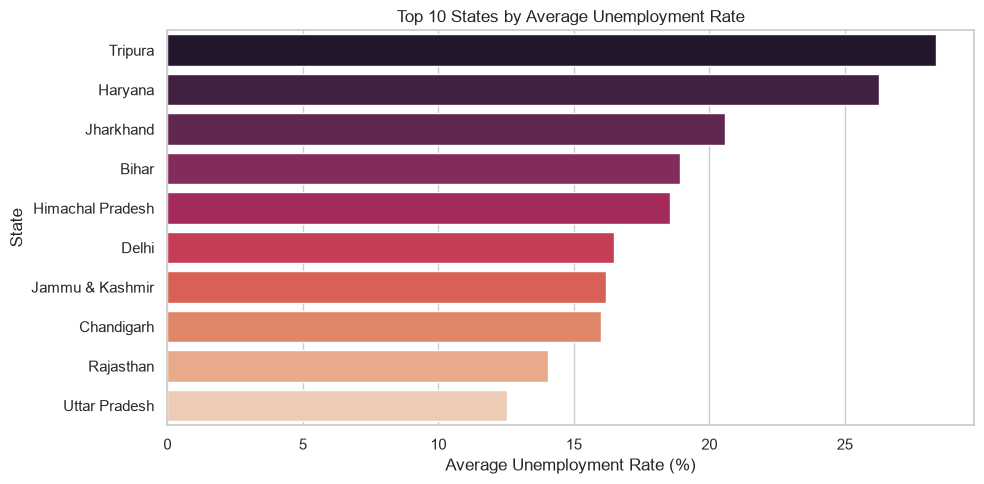

In [9]:
top10 = region_avg.head(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=top10, x="unemployment_rate", y="region", hue="region", palette="rocket", legend=False)
plt.title("Top 10 States by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

**Observations:** Tripura tops the list at 28.35%. These averages include the COVID months, so states hit hardest by the lockdown rank higher. Some states may also have high unemployment even before the pandemic. 

## 7. Correlation Heatmap

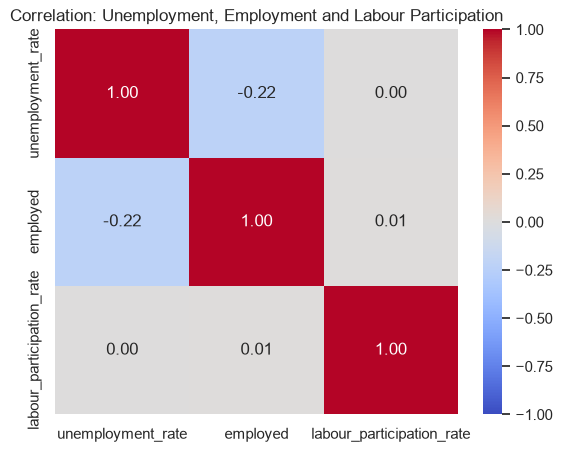

In [10]:
corr = df[["unemployment_rate", "employed", "labour_participation_rate"]].corr()

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation: Unemployment, Employment and Labour Participation")
plt.show()

## 8. Pre-COVID vs. Post-COVID Comparison

India's national lockdown began on **25 March 2020**, so I use that date to split the data into two periods.

In [11]:
LOCKDOWN_DATE = pd.Timestamp("2020-03-25")
df["period"] = np.where(df["date"] < LOCKDOWN_DATE, "Pre-COVID", "Post-COVID")

print(df["period"].value_counts())

period_stats = (
    df.groupby("period")[["unemployment_rate", "employed", "labour_participation_rate"]]
      .mean()
      .round(2)
      .loc[["Pre-COVID", "Post-COVID"]]
)
period_stats

period
Pre-COVID     536
Post-COVID    204
Name: count, dtype: int64


,unemployment_rate,employed,labour_participation_rate
period,,,
Pre-COVID,9.51,7466027.87,43.89
Post-COVID,17.77,6517203.34,39.33


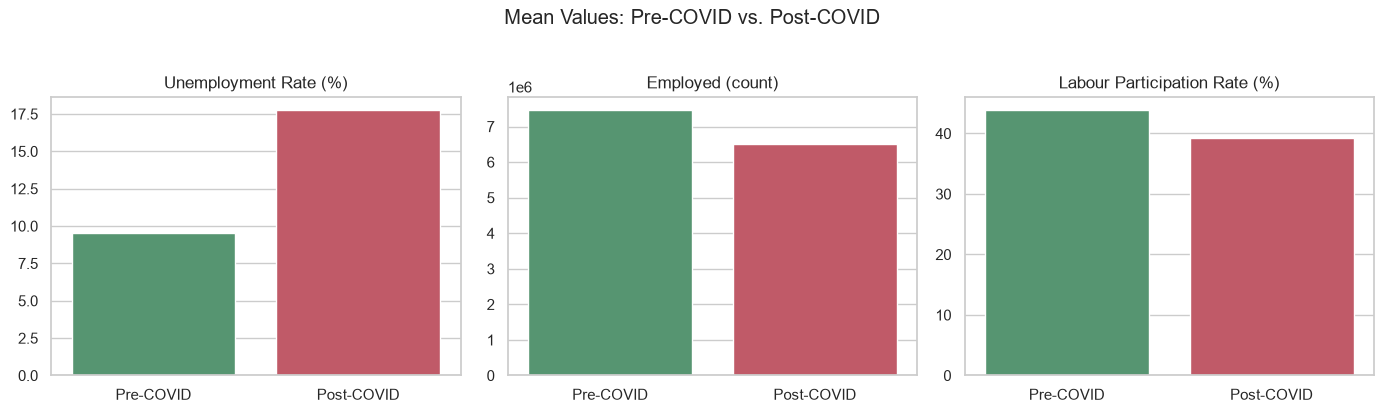

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(
    axes,
    ["unemployment_rate", "employed", "labour_participation_rate"],
    ["Unemployment Rate (%)", "Employed (count)", "Labour Participation Rate (%)"],
):
    sns.barplot(x=period_stats.index, y=period_stats[col], hue=period_stats.index,
                palette=["#4c9f70", "#d1495b"], legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Mean Values: Pre-COVID vs. Post-COVID", y=1.03)
plt.tight_layout()
plt.show()

**Observations:** The average unemployment rate rose from 9.51% before the 25 March 2020 lockdown to 17.77% after it, an increase of 8.26 percentage points (nearly double).  Because the post-COVID window includes the recovery months, the peak impact was larger than this average suggests.

### 8.1 Which states changed the most?

In [13]:
by_region = df.pivot_table(index="region", columns="period", values="unemployment_rate", aggfunc="mean")
by_region["change"] = by_region["Post-COVID"] - by_region["Pre-COVID"]
biggest = by_region.sort_values("change", ascending=False).head(10).round(2)
biggest

period,Post-COVID,Pre-COVID,change
region,,,
Puducherry,38.96,1.59,37.36
Tamil Nadu,25.40,2.84,22.57
Jharkhand,36.35,14.28,22.07
Bihar,31.63,13.83,17.80
Karnataka,15.28,3.23,12.05
Haryana,34.65,22.94,11.72
Kerala,17.95,6.99,10.96
Telangana,15.44,4.66,10.79
Madhya Pradesh,14.07,4.74,9.33


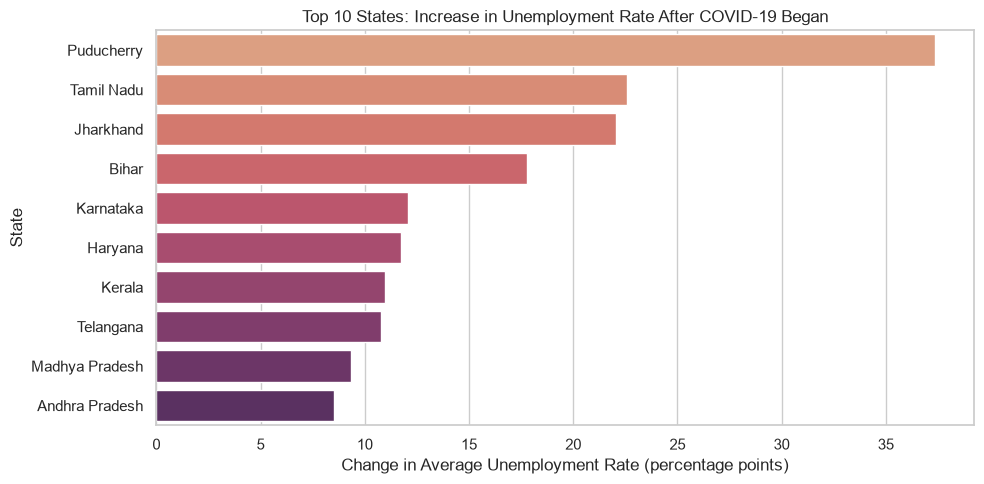

In [14]:
plot_df = biggest.reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df, x="change", y="region", hue="region", palette="flare", legend=False)
plt.title("Top 10 States: Increase in Unemployment Rate After COVID-19 Began")
plt.xlabel("Change in Average Unemployment Rate (percentage points)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

### 8.2 National trend with the lockdown marked

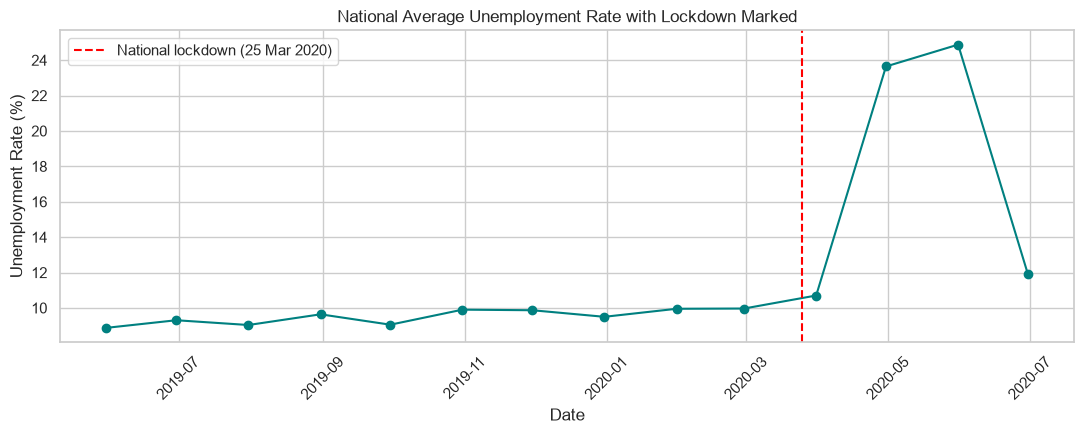

In [15]:
national = df.groupby("date")["unemployment_rate"].mean()

plt.figure(figsize=(11, 4.5))
plt.plot(national.index, national.values, marker="o", color="teal")
plt.axvline(LOCKDOWN_DATE, color="red", linestyle="--", label="National lockdown (25 Mar 2020)")
plt.title("National Average Unemployment Rate with Lockdown Marked")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observations:** The line stays fairly flat before the dashed lockdown marker, then jumps to a peak of 24.88% in May 2020.

## 9. Key Numbers (Calculated from the Data)

In [16]:
pre = period_stats.loc["Pre-COVID", "unemployment_rate"]
post = period_stats.loc["Post-COVID", "unemployment_rate"]
peak_month = national.idxmax()

print(f"Average unemployment rate pre-COVID : {pre:.2f}%")
print(f"Average unemployment rate post-COVID: {post:.2f}%")
print(f"Increase                            : {post - pre:.2f} percentage points")
print(f"National peak month                 : {peak_month.strftime('%B %Y')} ({national.max():.2f}%)")
print(f"Highest average-rate state          : {region_avg.index[0]} ({region_avg['unemployment_rate'].iloc[0]:.2f}%)")
print(f"Lowest average-rate state           : {region_avg.index[-1]} ({region_avg['unemployment_rate'].iloc[-1]:.2f}%)")
print(f"State with the biggest COVID jump   : {biggest.index[0]} (+{biggest['change'].iloc[0]:.2f} points)")

Average unemployment rate pre-COVID : 9.51%
Average unemployment rate post-COVID: 17.77%
Increase                            : 8.26 percentage points
National peak month                 : May 2020 (24.88%)
Highest average-rate state          : Tripura (28.35%)
Lowest average-rate state           : Meghalaya (4.80%)
State with the biggest COVID jump   : Puducherry (+37.36 points)


## 10. Conclusion

**Key findings**
1. **Regional differences are large.** Average unemployment ranged from 4.80% in Meghalaya to 28.35% in Tripura over the period, so unemployment in India is a strongly regional story.
2. **COVID-19 caused a sharp national spike.** The average unemployment rate rose from 9.51% before the lockdown to 17.77% after it, an increase of 8.26 percentage points (nearly double). The national average peaked in May 2020 at 24.88%.
3. **The impact was uneven.** Puducherry saw the biggest jump, with its average rising by 37.36 percentage points, far more than the national increase.
4. **The three measures tell different stories.** Employment and labour participation do not move in step with the unemployment rate, because people who stop looking for work leave the labour force rather than being counted as unemployed.

**Limitations**
- The data covers only about 14 months (May 2019 to June 2020), and the post-COVID period is just a few months, so long-term trends cannot be assessed.
- Rates are estimates, and the lockdown overlaps with other factors such as seasonality and migration.
- Averaging across states treats every state equally regardless of population size.
- Tripura's and Puducherry's figures are state averages and may be affected by how the data was collected for smaller states.
    